# Load dataset

In [13]:
import pandas as pd
df = pd.read_csv("/kaggle/input/datasets/thiwankachanditha/sold-data-sentiment-intent/sinhala_silver_labels.csv")

In [14]:
df.head()

,Sentence,Sentiment,intent_label,combined_label,nli_conf,conf_tier,nli_rule_agree,sample_weight
0,Ammage Adarayta❤️Eka Dawasak Madi Neda❤️🙏❤️,Negative,inquiry,Negative_inquiry,0.3559,rule,True,1.0
1,We need IPL Champions leak data offers ..pleas...,Neutral,inquiry,Neutral_inquiry,0.7913,high,False,1.0
2,chandimal.. uuu thama mulu tem ekama kaaa gaha...,Positive,inquiry,Positive_inquiry,0.4922,rule,False,1.0
3,Lebsack 49k dammama eka dawasak wath be,Negative,inquiry,Negative_inquiry,0.8232,rule,True,1.0
4,eth anith kattiya sathiyak withara online inna...,Neutral,other,Neutral_other,0.6918,mid,False,0.5


In [15]:
df.rename(columns={'Sentence':'text','Sentiment':'sentiment_label'}, inplace=True)

In [16]:
df.columns

Index(['text', 'sentiment_label', 'intent_label', 'combined_label', 'nli_conf',
       'conf_tier', 'nli_rule_agree', 'sample_weight'],
      dtype='object')

# Load Joint Model

In [17]:
import sys
sys.path.append('kaggle/input/datasets/thiwankachanditha/multi-head-attention-task')

In [18]:
import os

for dirname, _, filenames in os.walk('/kaggle/input/'):
    print(dirname)
    for filename in filenames:
        print("   ", filename)

/kaggle/input/
/kaggle/input/datasets
/kaggle/input/datasets/thiwankachanditha
/kaggle/input/datasets/thiwankachanditha/sentiment-intent-predicted
    sentiment_intent_predicted_1000.csv
/kaggle/input/datasets/thiwankachanditha/multi-head-attention-task
    train.py
    evaluate.py
    preprocess.py
    joint_model.py
    config.py
    predict.py
    dataset.py
/kaggle/input/datasets/thiwankachanditha/sold-data-sentiment-intent
    sinhala_silver_labels.csv


In [19]:
%run /kaggle/input/datasets/thiwankachanditha/multi-head-attention-task/config.py

In [20]:
# Cell 2 - See what datasets are attached
import os
print("Attached datasets:")
for d in os.listdir("/kaggle/input"):
    print(" ", d)
    for f in os.listdir("/kaggle/input/" + d):
        print("    --", f)


Attached datasets:
  datasets
    -- thiwankachanditha


In [21]:
# Cell 3 - Configuration
import torch, os

DATASET_NAME = "thiwankachanditha/sold-data-sentiment-intent"

TRAIN_CSV = "/kaggle/input/" + DATASET_NAME + "/train.csv"
VAL_CSV   = "/kaggle/input/" + DATASET_NAME + "/val.csv"
TEST_CSV  = "/kaggle/input/" + DATASET_NAME + "/test.csv"
FULL_CSV = "/kaggle/input/" + DATASET_NAME + "/sinhala_silver_labels.csv"

OUTPUT_DIR     = "/kaggle/working/outputs"
CHECKPOINT_DIR = "/kaggle/working/checkpoints"
MODEL_SAVE_DIR = "/kaggle/working/saved_model"
for d in [OUTPUT_DIR, CHECKPOINT_DIR, MODEL_SAVE_DIR]:
    os.makedirs(d, exist_ok=True)

TEXT_COL      = "text"
SENTIMENT_COL = "sentiment_label"
INTENT_COL    = "intent_label"

SENTIMENT_CLASSES = ["positive", "negative", "neutral", "conflict"]
INTENT_CLASSES    = ["suggestion", "complaint", "inquiry", "feedback", "greeting", "other"]

NUM_SENTIMENTS = len(SENTIMENT_CLASSES)
NUM_INTENTS    = len(INTENT_CLASSES)
BACKBONE       = "xlm-roberta-base"
MAX_LEN        = 128
BATCH_SIZE     = 32
EPOCHS         = 10
LR             = 2e-5
WEIGHT_DECAY   = 0.01
WARMUP_RATIO   = 0.1
DROPOUT        = 0.3
GRAD_CLIP      = 1.0
ALPHA          = 0.5
PATIENCE       = 3
SEED           = 42
SENT_SMOOTH    = 0.10
INTENT_SMOOTH  = 0.15
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Sentiment classes:", SENTIMENT_CLASSES)
print("Intent classes   :", INTENT_CLASSES)
print("Train CSV exists :", os.path.exists(TRAIN_CSV))
print("Val   CSV exists :", os.path.exists(VAL_CSV))
print("Test  CSV exists :", os.path.exists(TEST_CSV))


Device: cuda
Sentiment classes: ['positive', 'negative', 'neutral', 'conflict']
Intent classes   : ['suggestion', 'complaint', 'inquiry', 'feedback', 'greeting', 'other']
Train CSV exists : False
Val   CSV exists : False
Test  CSV exists : False


In [22]:
%pwd

'/kaggle/working'

In [24]:
import re, unicodedata, random
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

def clean_text(text):
    if not isinstance(text, str): return ""
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]", "", text)
    return re.sub(r"\s+", " ", text).strip()

# ── Label maps: string -> integer ──────────────────────────────
# These cover common casings. Add any new values you see printed.
SENTIMENT_MAP = {
    "positive": 0, "Positive": 0, "POSITIVE": 0,
    "negative": 1, "Negative": 1, "NEGATIVE": 1,
    "neutral":  2, "Neutral":  2, "NEUTRAL":  2,
    "conflict": 3, "Conflict": 3, "CONFLICT": 3,
}

INTENT_MAP = {
    "inquiry":     0, "Inquiry":     0, "INQUIRY":     0,
    "complaint": 1, "Complaint": 1, "COMPLAINT": 1,
    "suggestion":   2, "Suggestion":   2, "SUGGESTION":   2,
    "feedback":  3, "Feedback":  3, "FEEDBACK":  3,
    "greeting":  4, "Greeting":  4, "GREETING":  4,
    "other":     5, "Other":     5, "OTHER":     5,
}

def encode_labels(df):
    # Sentiment
    if not pd.api.types.is_integer_dtype(df[SENTIMENT_COL]):
        unknown_s = set(df[SENTIMENT_COL].unique()) - set(SENTIMENT_MAP.keys())
        if unknown_s:
            print("WARNING - Unknown sentiment values:", unknown_s)
            print("  Add them to SENTIMENT_MAP above and re-run this cell.")
        df[SENTIMENT_COL] = df[SENTIMENT_COL].map(SENTIMENT_MAP)

    # Intent
    if not pd.api.types.is_integer_dtype(df[INTENT_COL]):
        unknown_i = set(df[INTENT_COL].unique()) - set(INTENT_MAP.keys())
        if unknown_i:
            print("WARNING - Unknown intent values:", unknown_i)
            print("  Add them to INTENT_MAP above and re-run this cell.")
        df[INTENT_COL] = df[INTENT_COL].map(INTENT_MAP)

    # Drop rows where mapping failed (NaN = label not in map)
    before = len(df)
    df = df.dropna(subset=[SENTIMENT_COL, INTENT_COL])
    dropped = before - len(df)
    if dropped > 0:
        print(f"Dropped {dropped} rows with unmapped labels")

    df[SENTIMENT_COL] = df[SENTIMENT_COL].astype(int)
    df[INTENT_COL]    = df[INTENT_COL].astype(int)
    return df

def load_and_clean(path):
    df = pd.read_csv("/kaggle/input/datasets/thiwankachanditha/sold-data-sentiment-intent/sinhala_silver_labels.csv")
    df.rename(columns={'Sentence':'text', 'intent':'intent_label', 'sentiment':'sentiment_label'}, inplace=True)

    # Rename columns to standard names
    df.rename(columns={
        "Sentence":  "text",  "sentence":  "text",  "Text": "text",
        "intent":    "intent_label",   "Intent":    "intent_label",
        "sentiment": "sentiment_label","Sentiment": "sentiment_label",
    }, inplace=True)

    # Print raw unique values so you can verify the maps are correct
    print(f"\nFile: {path}")
    print(f"  Columns          : {list(df.columns)}")
    print(f"  Sentiment unique : {sorted(df[SENTIMENT_COL].astype(str).unique())}")
    print(f"  Intent unique    : {sorted(df[INTENT_COL].astype(str).unique())}")

    df[TEXT_COL] = df[TEXT_COL].apply(clean_text)
    df = encode_labels(df)
    df = df[df[TEXT_COL].str.len() > 0].reset_index(drop=True)
    print(f"  Rows after clean : {len(df)}")
    return df

# ── Load and split ─────────────────────────────────────────────
df_all = load_and_clean(FULL_CSV)

df_train, df_temp = train_test_split(
    df_all, test_size=0.30,
    stratify=df_all[SENTIMENT_COL], random_state=SEED)

df_val, df_test = train_test_split(
    df_temp, test_size=0.50,
    stratify=df_temp[SENTIMENT_COL], random_state=SEED)

df_train.to_csv("/kaggle/working/train.csv", index=False)
df_val.to_csv(  "/kaggle/working/val.csv",   index=False)
df_test.to_csv( "/kaggle/working/test.csv",  index=False)

TRAIN_CSV = "/kaggle/working/train.csv"
VAL_CSV   = "/kaggle/working/val.csv"
TEST_CSV  = "/kaggle/working/test.csv"

print(f"\nSplit complete: Train={len(df_train)}  Val={len(df_val)}  Test={len(df_test)}")

# Distribution check
for name, df in [("TRAIN", df_train), ("VAL", df_val), ("TEST", df_test)]:
    print(f"\n-- {name} Sentiment --")
    for idx, cnt in df[SENTIMENT_COL].value_counts().sort_index().items():
        print(f"  [{idx}] {SENTIMENT_CLASSES[idx]:<12} {cnt:>5} ({cnt/len(df)*100:.1f}%)")
    print(f"-- {name} Intent --")
    for idx, cnt in df[INTENT_COL].value_counts().sort_index().items():
        print(f"  [{idx}] {INTENT_CLASSES[idx]:<12} {cnt:>5} ({cnt/len(df)*100:.1f}%)")

df_train[[TEXT_COL, SENTIMENT_COL, INTENT_COL]].head()


File: /kaggle/input/thiwankachanditha/sold-data-sentiment-intent/sinhala_silver_labels.csv
  Columns          : ['text', 'sentiment_label', 'intent_label', 'combined_label', 'nli_conf', 'conf_tier', 'nli_rule_agree', 'sample_weight']
  Sentiment unique : ['Conflict', 'Negative', 'Neutral', 'Positive']
  Intent unique    : ['complaint', 'feedback', 'greeting', 'inquiry', 'other', 'suggestion']
  Rows after clean : 5881

Split complete: Train=4116  Val=882  Test=883

-- TRAIN Sentiment --
  [0] positive       278 (6.8%)
  [1] negative      1074 (26.1%)
  [2] neutral       2721 (66.1%)
  [3] conflict        43 (1.0%)
-- TRAIN Intent --
  [0] suggestion    2246 (54.6%)
  [1] complaint      382 (9.3%)
  [2] inquiry        314 (7.6%)
  [3] feedback       562 (13.7%)
  [4] greeting       401 (9.7%)
  [5] other          211 (5.1%)

-- VAL Sentiment --
  [0] positive        59 (6.7%)
  [1] negative       230 (26.1%)
  [2] neutral        583 (66.1%)
  [3] conflict        10 (1.1%)
-- VAL Intent

,text,sentiment_label,intent_label
4459,dr Gerhold i hv problem tody at morning my bal...,2,1
2984,Mage nethiuna sim akak thiyanawa aka apahu gan...,2,0
481,Pictures from the massive celebration to welco...,2,4
2287,Lebsack mega run wage game ekk onee.............,2,5
1903,"Thank you Hilpert for your new Rs 21/= , 2GB pack",0,3


In [25]:
# Cell 5 - Tokenizer, Dataset, DataLoaders
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

class SinhalaJointDataset(Dataset):
    def __init__(self, texts, sent_lbl, intent_lbl, tokenizer, max_len=MAX_LEN):
        self.texts = texts; self.sent_lbl = sent_lbl
        self.intent_lbl = intent_lbl; self.tok = tokenizer; self.max_len = max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        enc = self.tok(str(self.texts[idx]), max_length=self.max_len,
                       padding="max_length", truncation=True, return_tensors="pt")
        return {
            "input_ids":       enc["input_ids"].squeeze(0),
            "attention_mask":  enc["attention_mask"].squeeze(0),
            "sentiment_label": torch.tensor(self.sent_lbl[idx],   dtype=torch.long),
            "intent_label":    torch.tensor(self.intent_lbl[idx], dtype=torch.long),
        }

def make_loader(df, tok, shuffle=False):
    ds = SinhalaJointDataset(df[TEXT_COL].tolist(), df[SENTIMENT_COL].tolist(),
                              df[INTENT_COL].tolist(), tok)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2, pin_memory=True)

print("Loading tokenizer (small download ~5 MB)...")
tokenizer = AutoTokenizer.from_pretrained(BACKBONE)
print("Vocab size:", tokenizer.vocab_size)

sample = df_train[TEXT_COL].iloc[0]
print("Sample text:", sample)
print("Tokens     :", tokenizer.tokenize(sample))

train_loader = make_loader(df_train, tokenizer, shuffle=True)
val_loader   = make_loader(df_val,   tokenizer)
test_loader  = make_loader(df_test,  tokenizer)
print("Train batches:", len(train_loader), " Val:", len(val_loader), " Test:", len(test_loader))


Loading tokenizer (small download ~5 MB)...


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Vocab size: 250002
Sample text: dr Gerhold i hv problem tody at morning my balance is on 33.xx and the data balance is 18mb anytime so i surf in net about 5 min after i checked balance now my balance is 2.33 and data balance is 2.82mb
Tokens     : ['▁dr', '▁Ger', 'hold', '▁i', '▁', 'hv', '▁problem', '▁to', 'dy', '▁at', '▁morning', '▁my', '▁balance', '▁is', '▁on', '▁33.', 'xx', '▁and', '▁the', '▁data', '▁balance', '▁is', '▁18', 'mb', '▁any', 'time', '▁so', '▁i', '▁surf', '▁in', '▁net', '▁about', '▁5', '▁min', '▁after', '▁i', '▁check', 'ed', '▁balance', '▁now', '▁my', '▁balance', '▁is', '▁2.', '33', '▁and', '▁data', '▁balance', '▁is', '▁2.', '82', 'mb']
Train batches: 129  Val: 28  Test: 28


In [26]:
# Cell 6 - Model architecture
import torch.nn as nn
from transformers import AutoModel

class JointModel(nn.Module):
    def __init__(self, backbone=BACKBONE, ns=NUM_SENTIMENTS, ni=NUM_INTENTS, do=DROPOUT):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(backbone)
        h = self.encoder.config.hidden_size
        # Simpler head: sentiment labels cleaner (79% acc annotator)
        self.sent_head = nn.Sequential(nn.Dropout(do), nn.Linear(h, ns))
        # Deeper head: intent labels noisier (3-stage pipeline)
        self.intent_head = nn.Sequential(
            nn.Dropout(do), nn.Linear(h, 256),
            nn.GELU(), nn.Dropout(do), nn.Linear(256, ni))
    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:, 0, :]
        return self.sent_head(cls), self.intent_head(cls)
    def get_param_groups(self, lr, wd):
        nd    = ["bias", "LayerNorm.weight"]
        enc   = list(self.encoder.named_parameters())
        heads = list(self.sent_head.named_parameters()) + list(self.intent_head.named_parameters())
        return [
            {"params": [p for n,p in enc   if not any(d in n for d in nd)], "lr": lr,      "weight_decay": wd},
            {"params": [p for n,p in enc   if     any(d in n for d in nd)], "lr": lr,      "weight_decay": 0.0},
            {"params": [p for n,p in heads if not any(d in n for d in nd)], "lr": lr * 10, "weight_decay": wd},
            {"params": [p for n,p in heads if     any(d in n for d in nd)], "lr": lr * 10, "weight_decay": 0.0},
        ]

print("Loading XLM-R backbone (~1.1 GB download on first run)...")
model = JointModel().to(DEVICE)
print(f"Model on {DEVICE}  Params: {sum(p.numel() for p in model.parameters()):,}")
d = torch.zeros(2, MAX_LEN, dtype=torch.long).to(DEVICE)
m = torch.ones(2,  MAX_LEN, dtype=torch.long).to(DEVICE)
s, i = model(d, m)
print(f"Forward pass OK -> sentiment {s.shape}  intent {i.shape}")


Loading XLM-R backbone (~1.1 GB download on first run)...


model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model on cuda  Params: 278,245,130
Forward pass OK -> sentiment torch.Size([2, 4])  intent torch.Size([2, 6])


In [27]:
# Cell 7 - Training loop with early stopping
from transformers import get_linear_schedule_with_warmup

sc = nn.CrossEntropyLoss(label_smoothing=SENT_SMOOTH)
ic = nn.CrossEntropyLoss(label_smoothing=INTENT_SMOOTH)

def jloss(sl, il, slbl, ilbl):
    ls = sc(sl, slbl); li = ic(il, ilbl)
    return ALPHA * ls + (1 - ALPHA) * li, ls, li

optimizer   = torch.optim.AdamW(model.get_param_groups(LR, WEIGHT_DECAY))
total_steps = len(train_loader) * EPOCHS
scheduler   = get_linear_schedule_with_warmup(optimizer, int(total_steps * WARMUP_RATIO), total_steps)

def train_ep():
    model.train(); tot = tsl = til = 0.0
    for b in train_loader:
        ids   = b["input_ids"].to(DEVICE)
        mask  = b["attention_mask"].to(DEVICE)
        s_lbl = b["sentiment_label"].to(DEVICE)
        i_lbl = b["intent_label"].to(DEVICE)
        slog, ilog = model(ids, mask)
        loss, ls, li = jloss(slog, ilog, s_lbl, i_lbl)
        optimizer.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step(); scheduler.step()
        tot += loss.item(); tsl += ls.item(); til += li.item()
    n = len(train_loader)
    return tot/n, tsl/n, til/n

def val_ep():
    model.eval(); tot = cs = ci = jc = total = 0
    with torch.no_grad():
        for b in val_loader:
            ids   = b["input_ids"].to(DEVICE)
            mask  = b["attention_mask"].to(DEVICE)
            s_lbl = b["sentiment_label"].to(DEVICE)
            i_lbl = b["intent_label"].to(DEVICE)
            slog, ilog = model(ids, mask)
            loss, ls, li = jloss(slog, ilog, s_lbl, i_lbl)
            tot += loss.item()
            sp = slog.argmax(1); ip = ilog.argmax(1)
            cs    += (sp == s_lbl).sum().item()
            ci    += (ip == i_lbl).sum().item()
            jc    += ((sp == s_lbl) & (ip == i_lbl)).sum().item()
            total += s_lbl.size(0)
    return {"loss": tot/len(val_loader), "s_acc": cs/total, "i_acc": ci/total, "j_acc": jc/total}

best_loss = float("inf"); pat = 0
best_ckpt = os.path.join(CHECKPOINT_DIR, "best.pt"); history = []
print("=" * 50)
print("Starting Training")
print("=" * 50)

for epoch in range(1, EPOCHS + 1):
    tl, tsl, til = train_ep()
    vm = val_ep()
    history.append({"epoch": epoch, "train_loss": tl, **vm})
    print(f"\nEpoch {epoch}/{EPOCHS}")
    print(f"  Train  loss={tl:.4f}  sent={tsl:.4f}  intent={til:.4f}")
    print(f"  Val    loss={vm['loss']:.4f}  sent_acc={vm['s_acc']:.4f}  intent_acc={vm['i_acc']:.4f}  joint_acc={vm['j_acc']:.4f}")
    if vm["loss"] < best_loss:
        best_loss = vm["loss"]; pat = 0
        torch.save({"epoch": epoch, "model_state": model.state_dict(), "val_loss": best_loss}, best_ckpt)
        print("  [SAVED] Best checkpoint updated")
    else:
        pat += 1; print(f"  No improvement ({pat}/{PATIENCE})")
        if pat >= PATIENCE:
            print(f"Early stopping at epoch {epoch}"); break

print("Training complete!")

Starting Training

Epoch 1/10
  Train  loss=1.3976  sent=1.2088  intent=1.5864
  Val    loss=1.1283  sent_acc=0.6610  intent_acc=0.5862  joint_acc=0.4274
  [SAVED] Best checkpoint updated

Epoch 2/10
  Train  loss=1.0550  sent=0.8740  intent=1.2360
  Val    loss=0.9495  sent_acc=0.7506  intent_acc=0.7426  joint_acc=0.5714
  [SAVED] Best checkpoint updated

Epoch 3/10
  Train  loss=0.9189  sent=0.7686  intent=1.0691
  Val    loss=0.9027  sent_acc=0.7404  intent_acc=0.7653  joint_acc=0.5805
  [SAVED] Best checkpoint updated

Epoch 4/10
  Train  loss=0.8512  sent=0.7343  intent=0.9681
  Val    loss=0.8794  sent_acc=0.7562  intent_acc=0.8061  joint_acc=0.6213
  [SAVED] Best checkpoint updated

Epoch 5/10
  Train  loss=0.7931  sent=0.6902  intent=0.8960
  Val    loss=0.8884  sent_acc=0.7653  intent_acc=0.8005  joint_acc=0.6293
  No improvement (1/3)

Epoch 6/10
  Train  loss=0.7534  sent=0.6556  intent=0.8511
  Val    loss=0.8796  sent_acc=0.7619  intent_acc=0.8084  joint_acc=0.6293
  No im

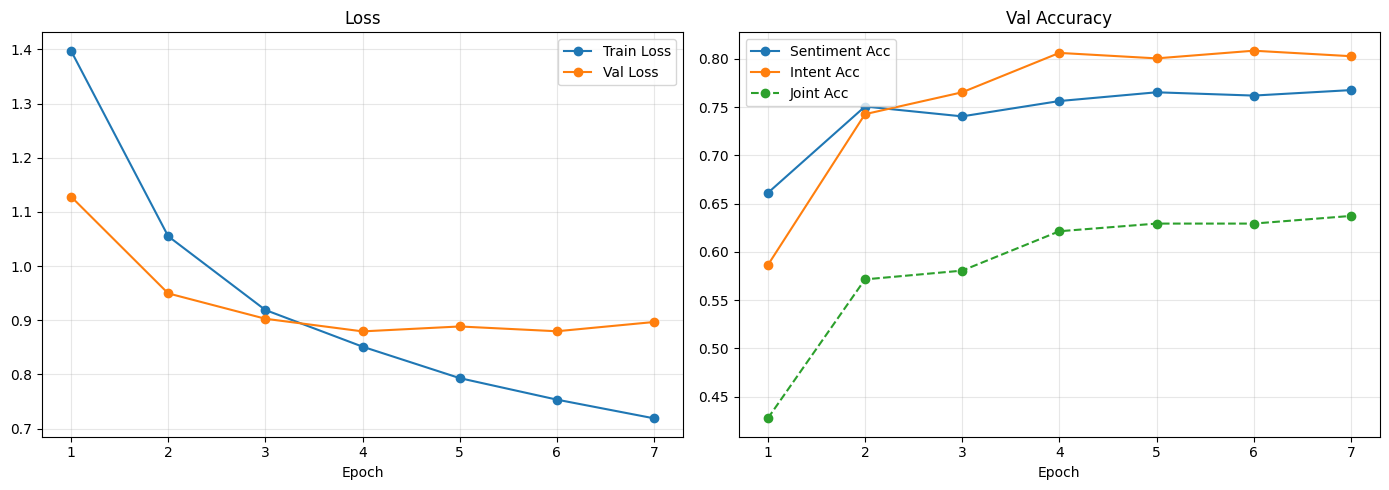

In [28]:
# Cell 8 - Training curves
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep = [h["epoch"] for h in history]

axes[0].plot(ep, [h["train_loss"] for h in history], "o-", label="Train Loss")
axes[0].plot(ep, [h["loss"]       for h in history], "o-", label="Val Loss")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep, [h["s_acc"] for h in history], "o-",  label="Sentiment Acc")
axes[1].plot(ep, [h["i_acc"] for h in history], "o-",  label="Intent Acc")
axes[1].plot(ep, [h["j_acc"] for h in history], "o--", label="Joint Acc")
axes[1].set_title("Val Accuracy"); axes[1].set_xlabel("Epoch")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/training_curves.png", dpi=150)
plt.show()

In [29]:
# Cell 9 - Load best checkpoint and evaluate on test set
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns

ckpt = torch.load(best_ckpt, map_location=DEVICE)
model.load_state_dict(ckpt["model_state"])
model.eval()
print(f"Loaded epoch {ckpt['epoch']}  val_loss={ckpt['val_loss']:.4f}")

all_sp, all_ip, all_sl, all_il = [], [], [], []
with torch.no_grad():
    for b in test_loader:
        ids  = b["input_ids"].to(DEVICE)
        mask = b["attention_mask"].to(DEVICE)
        slog, ilog = model(ids, mask)
        all_sp.extend(slog.argmax(1).cpu().tolist())
        all_ip.extend(ilog.argmax(1).cpu().tolist())
        all_sl.extend(b["sentiment_label"].tolist())
        all_il.extend(b["intent_label"].tolist())

all_sp = np.array(all_sp); all_ip = np.array(all_ip)
all_sl = np.array(all_sl); all_il = np.array(all_il)

print("\n=== SENTIMENT ===")
print(classification_report(all_sl, all_sp, target_names=SENTIMENT_CLASSES, digits=4))
print("\n=== INTENT ===")
print(classification_report(all_il, all_ip, target_names=INTENT_CLASSES, digits=4))

joint_acc = np.sum((all_sp == all_sl) & (all_ip == all_il)) / len(all_sl)
print(f"Joint Accuracy     : {joint_acc:.4f}")
print(f"Sentiment Macro-F1 : {f1_score(all_sl, all_sp, average='macro'):.4f}")
print(f"Intent    Macro-F1 : {f1_score(all_il, all_ip, average='macro'):.4f}")

Loaded epoch 4  val_loss=0.8794

=== SENTIMENT ===
              precision    recall  f1-score   support

    positive     0.6957    0.2667    0.3855        60
    negative     0.7200    0.4696    0.5684       230
     neutral     0.7634    0.9281    0.8377       584
    conflict     0.0000    0.0000    0.0000         9

    accuracy                         0.7542       883
   macro avg     0.5448    0.4161    0.4479       883
weighted avg     0.7397    0.7542    0.7283       883


=== INTENT ===
              precision    recall  f1-score   support

  suggestion     0.8972    0.9322    0.9144       487
   complaint     0.7534    0.5978    0.6667        92
     inquiry     0.6190    0.5909    0.6047        66
    feedback     0.5985    0.7885    0.6805       104
    greeting     0.8202    0.8690    0.8439        84
       other     0.8000    0.2400    0.3692        50

    accuracy                         0.8097       883
   macro avg     0.7481    0.6697    0.6799       883
weighted a

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


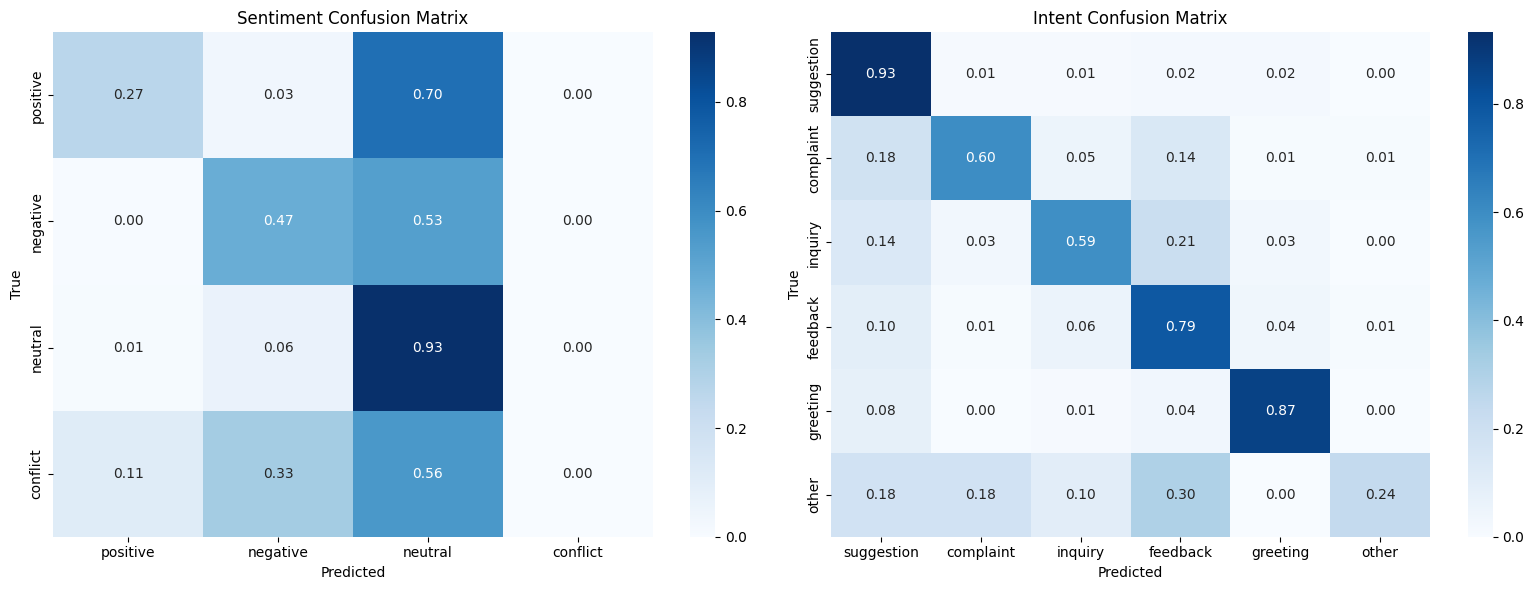

In [30]:
# Cell 10 - Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, preds, labels, classes, title in [
    (axes[0], all_sp, all_sl, SENTIMENT_CLASSES, "Sentiment"),
    (axes[1], all_ip, all_il, INTENT_CLASSES,    "Intent"),
]:
    cm = confusion_matrix(labels, preds).astype(float)
    cm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm, annot=True, fmt=".2f",
                xticklabels=classes, yticklabels=classes, cmap="Blues", ax=ax)
    ax.set_title(title + " Confusion Matrix")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(OUTPUT_DIR + "/confusion_matrices.png", dpi=150)
plt.show()

In [31]:
# Cell 11 - Save model
model.encoder.save_pretrained(MODEL_SAVE_DIR)
tokenizer.save_pretrained(MODEL_SAVE_DIR)
torch.save(model.state_dict(), MODEL_SAVE_DIR + "/joint_heads.pt")
print("Saved to:", MODEL_SAVE_DIR)
for f in os.listdir(MODEL_SAVE_DIR):
    mb = os.path.getsize(MODEL_SAVE_DIR + "/" + f) / 1e6
    print(f"  {f}  ({mb:.1f} MB)")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to: /kaggle/working/saved_model
  joint_heads.pt  (1113.1 MB)
  config.json  (0.0 MB)
  model.safetensors  (1112.2 MB)
  tokenizer_config.json  (0.0 MB)
  tokenizer.json  (16.8 MB)


In [32]:
# Cell 12 - Predict on new unseen text
def predict(text):
    model.eval()
    text = clean_text(str(text))
    enc  = tokenizer(text, max_length=MAX_LEN, padding="max_length",
                     truncation=True, return_tensors="pt")
    with torch.no_grad():
        slog, ilog = model(enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE))
    sp = torch.softmax(slog, -1).cpu().numpy()[0]
    ip = torch.softmax(ilog, -1).cpu().numpy()[0]
    return {
        "text":                 text,
        "sentiment":            SENTIMENT_CLASSES[sp.argmax()],
        "sentiment_confidence": round(float(sp.max()), 4),
        "intent":               INTENT_CLASSES[ip.argmax()],
        "intent_confidence":    round(float(ip.max()), 4),
        "sentiment_probs": {c: round(float(p), 4) for c, p in zip(SENTIMENT_CLASSES, sp)},
        "intent_probs":    {c: round(float(p), 4) for c, p in zip(INTENT_CLASSES,   ip)},
    }

def pretty_print(r):
    print("\n" + "-"*50)
    print(f"  Text      : {r['text']}")
    print(f"  Sentiment : {r['sentiment']:<12} (conf: {r['sentiment_confidence']:.1%})")
    print(f"  Intent    : {r['intent']:<12} (conf: {r['intent_confidence']:.1%})")
    print("  Sentiment probs:")
    for c, p in r["sentiment_probs"].items():
        print(f"    {c:<12} {p:.4f}")
    print("  Intent probs:")
    for c, p in r["intent_probs"].items():
        print(f"    {c:<12} {p:.4f}")

# Test with sample texts - replace with your own Sinhala text
samples = [
    "meka harima wadiyai mata refund ekk one",
    "oyage service eka best godak stuthi",
    "delivery date eka kawadad",
    "me product eka use karanne kohomad",
]
for text in samples:
    pretty_print(predict(text))


--------------------------------------------------
  Text      : meka harima wadiyai mata refund ekk one
  Sentiment : neutral      (conf: 88.3%)
  Intent    : suggestion   (conf: 91.7%)
  Sentiment probs:
    positive     0.0233
    negative     0.0758
    neutral      0.8831
    conflict     0.0179
  Intent probs:
    suggestion   0.9174
    complaint    0.0192
    inquiry      0.0170
    feedback     0.0147
    greeting     0.0181
    other        0.0136

--------------------------------------------------
  Text      : oyage service eka best godak stuthi
  Sentiment : neutral      (conf: 77.9%)
  Intent    : suggestion   (conf: 91.5%)
  Sentiment probs:
    positive     0.0400
    negative     0.1529
    neutral      0.7789
    conflict     0.0282
  Intent probs:
    suggestion   0.9155
    complaint    0.0179
    inquiry      0.0160
    feedback     0.0190
    greeting     0.0171
    other        0.0145

--------------------------------------------------
  Text      : delivery dat

In [33]:
inference_data = [
    "හෙලෝ 😊 කොහොමද?",
    "මට order එකක් දාන්න පුළුවන්ද?",
    "මේ app එක හොඳයි 👍",
    "service එක ඉතාම නරකයි 😡",
    "ඔයාගේ help එකට thanks 🙏",
    "මේ feature එක add කරන්න පුළුවන්ද? 🤔",
    "ඇයි මේක load වෙන්නේ නැත්තේ? 😕",
    "සුභ උදෑසනක් 🌅",
    "delivery එක late 😤",
    "මේක average වගේ 😐",

    "මට bill එක check කරන්න ඕනේ 🧾",
    "ඔබට ස්තූතියි ❤️",
    "system එක crash වෙනවා 😡",
    "මේක improve කරන්න පුළුවන් 💡",
    "hi 👋",
    "මට password reset කරගන්න ඕනේ 🔑",
    "response එක slow 😒",
    "great service 👍🔥",
    "මේක හරිද කියලා දන්නේ නැහැ 🤷",
    "hello 😊",

    "app එක awesome 😍",
    "මේක bug එකක් වගේ 🐞",
    "please help කරන්න 🙏",
    "service එක okay 😐",
    "delivery delay වෙලා 😠",
    "nice work 👏",
    "error එක fix කරන්න 😤",
    "suggest එකක් තියෙනවා 💡",
    "good morning ☀️",
    "මට info එකක් ඕනේ 📄",

    "thank you so much ❤️",
    "login වෙන්න බැහැ 😡",
    "app එක improve වෙලා 👍",
    "මේක confusing 😕",
    "hi there 😄",
    "reset link එක නැහැ 😤",
    "feedback එකක් දෙන්නම් ✍️",
    "bad experience 😠",
    "neutral feel එකක් 😐",
    "help needed 🙏",

    "super app 😍🔥",
    "issue එක solve කරන්න 🛠️",
    "suggestion එකක් තියෙනවා 💡",
    "hello hello 😄",
    "response slow 😒",
    "good job 👍",
    "error message එක එනවා 😡",
    "info provide කරන්න 📄",
    "okay experience 😐",
    "hi 😊",

    "excellent service 🌟",
    "app crash වෙනවා 😤",
    "add new feature 💡",
    "hello guys 👋",
    "slow performance 😒",
    "thanks a lot 🙏",
    "bug fix කරන්න 🐞",
    "average system 😐",
    "inquiry එකක් තියෙනවා 🤔",
    "good evening 🌙",

    "really helpful ❤️",
    "terrible service 😡",
    "improve UI 💡",
    "hi hi 😄",
    "delay issue 😠",
    "nice experience 👍",
    "problem එක solve කරන්න 😤",
    "neutral response 😐",
    "need details 📄",
    "hello 😊",

    "awesome work 🔥",
    "not working 😡",
    "suggestion add කරන්න 💡",
    "hi team 👋",
    "slow loading 😒",
    "thanks 🙏",
    "error fix කරන්න 🛠️",
    "okay system 😐",
    "more info needed 🤔",
    "hello there 😊",

    "great job 👍",
    "bad support 😠",
    "new feature please 💡",
    "hi 😊",
    "delay again 😤",
    "nice app ❤️",
    "issue unresolved 😡",
    "average experience 😐",
    "details please 📄",
    "hello 👋",

    "super service 🌟",
    "app not responding 😡",
    "improve speed 💡",
    "hi everyone 😊",
    "slow app 😒",
    "thank you 🙏",
    "bug issue 🐞",
    "neutral feedback 😐",
    "need help 🤔",
    "hello 😊"
]

In [34]:
for text in inference_data:
    pretty_print(predict(text))


--------------------------------------------------
  Text      : හෙලෝ 😊 කොහොමද?
  Sentiment : neutral      (conf: 89.8%)
  Intent    : greeting     (conf: 79.3%)
  Sentiment probs:
    positive     0.0612
    negative     0.0243
    neutral      0.8985
    conflict     0.0160
  Intent probs:
    suggestion   0.1298
    complaint    0.0181
    inquiry      0.0221
    feedback     0.0251
    greeting     0.7926
    other        0.0123

--------------------------------------------------
  Text      : මට order එකක් දාන්න පුළුවන්ද?
  Sentiment : neutral      (conf: 94.0%)
  Intent    : suggestion   (conf: 89.2%)
  Sentiment probs:
    positive     0.0161
    negative     0.0297
    neutral      0.9402
    conflict     0.0140
  Intent probs:
    suggestion   0.8918
    complaint    0.0172
    inquiry      0.0301
    feedback     0.0192
    greeting     0.0212
    other        0.0204

--------------------------------------------------
  Text      : මේ app එක හොඳයි 👍
  Sentiment : positive   